# Evaluación de datasets geográficos nuevos: aeropuertos, biomas, ciudades y agua

**Contexto**: en TP2, `hipotesis-agua-ciudades-aeropuertos.ipynb` testeó si la distancia al agua, a un área urbana o
a un aeropuerto se asocia al error de pronóstico, y encontró soporte parcial (agua y aeropuerto asociados al error de
temperatura/HR/punto de rocío; área urbana asociada sobre todo al error de viento, con CENTERPOINT -la red de Houston,
148 de las 500 estaciones de TP2- como confusión). Pero la introducción de esa misma hipótesis menciona un cuarto
dataset -EPA Ecoregions (biomas)- que **nunca se usó**: ni el ETL (`atributos_geograficos.py`) lo lee, ni aparece en
ningún test.

Ahora estos 4 datasets están de nuevo en `TP3/data/raw/`, algunos con archivos adicionales a los que tenía TP2. La
pregunta de este notebook es doble:

1. **¿Se sostienen los hallazgos de TP2** sobre agua/aeropuerto/área urbana en el dataset de TP3 -distinta ventana
   temporal y, como se va a ver, una composición de redes bastante distinta-?
2. **¿Aporta algo nuevo** el dataset que TP2 nunca testeó (biomas), o los archivos nuevos que vinieron junto con los
   que ya se habían usado?

El objetivo final es decidir, para cada dataset, si conviene sumarlo como feature estático de estación a los modelos
de corrección de sesgo de la Etapa A (consigna TP3, sección 3: *"Feature Engineering: crear variables derivadas que
consideren necesarias"*) -no repetir el mismo test por repetirlo.

**Mismo criterio que TP2**: unidad de análisis = una estación (MAE y sesgo con signo promediados, no por hora, para
no inflar el n con mediciones autocorrelacionadas); mínimo 30 pares obs-pronóstico por estación; tests no
paramétricos (Spearman, Mann-Whitney y, acá además, Kruskal-Wallis para el bioma, que tiene más de 2 categorías) con
corrección FDR de Benjamini-Hochberg por comparaciones múltiples. Convención de signo: error = pronosticado −
observado (igual que en TP2).

In [5]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
from utils import AZUL, NARANJA, GRIS_TEXTO, aplicar_estilo, cargar_mediciones_limpias

In [6]:
RAW = '../data/raw/'
PROCESSED = '../data/processed/'
OUT = '../data/out/atributos_geograficos/'
CRS_METRICO = 'EPSG:5070'  # Albers equivalente para EE.UU. contiguo, igual que TP2

aplicar_estilo()
figuras = {}

## 1. Estaciones y variable de error (una fila por estación)

Mismo armado que TP2: se agrupa `mediciones_limpias.csv` por estación, se promedia el error con signo y el error
absoluto de las 4 variables continuas, y se exige un mínimo de 30 pares obs-pronóstico (cualquier horizonte) para
que esa estación entre al análisis.

In [7]:
MIN_OBS = 30

VARIABLES = {
    'temp_c': 'Temperatura (°C)',
    'rh_pct': 'Humedad relativa (pp)',
    'dewpoint_c': 'Punto de rocío (°C)',
    'windspeed_kmh': 'Viento (km/h)',
}
columnas_error = [f'{pref}_{v}' for v in VARIABLES for pref in ('error', 'abs_error')]

mp = cargar_mediciones_limpias(PROCESSED + 'mediciones_limpias.csv')
agrupado = mp.groupby('station_id')

por_estacion = agrupado[columnas_error].mean()
por_estacion['n_obs'] = agrupado.size()
por_estacion['red'] = agrupado['red'].first()
por_estacion['latitud'] = agrupado['latitud'].first()
por_estacion['longitud'] = agrupado['longitud'].first()
por_estacion['estado'] = agrupado['estado'].first()

pocas_obs = por_estacion['n_obs'] < MIN_OBS
datos = por_estacion[~pocas_obs].copy()

print(f'{len(datos)} estaciones con >= {MIN_OBS} pares obs-pronóstico ({pocas_obs.sum()} excluidas por pocas observaciones)')
print('\nRedes más grandes (para tener presente al leer la sección de área urbana más adelante):')
print(datos['red'].value_counts().head(6))

498 estaciones con >= 30 pares obs-pronóstico (0 excluidas por pocas observaciones)

Redes más grandes (para tener presente al leer la sección de área urbana más adelante):
red
OTHER-MTR    187
ASOS-HFM     136
RAWS          57
TG            44
APRSWXNET     18
ASOS          14
Name: count, dtype: int64


## 2. Geometría de las estaciones y distancia genérica

Mismo helper que `ETL/atributos_geograficos.py`: distancia (km) de cada estación al elemento más cercano de una capa,
reproyectando a un CRS métrico (Albers) antes de medir. Se reutiliza para agua, aeropuerto y área urbana -lo único
que cambia entre esas tres secciones es la capa.

In [8]:
puntos = gpd.GeoDataFrame(datos, geometry=gpd.points_from_xy(datos['longitud'], datos['latitud']), crs='EPSG:4326')


def distancia_km(puntos, capa):
    """Distancia (km) de cada punto al elemento más cercano de `capa` (0 si el punto cae adentro)."""
    cercano = gpd.sjoin_nearest(
        puntos.to_crs(CRS_METRICO)[['geometry']],
        capa.to_crs(CRS_METRICO)[['geometry']],
        how='left', distance_col='dist_m')
    cercano = cercano[~cercano.index.duplicated()]  # empates a igual distancia
    return (cercano['dist_m'] / 1000).round(3)

## 3. Agua (Natural Earth 10m) -ya validado en TP2

Costa (`ne_10m_coastline`, línea, solo distancia) + lagos (`ne_10m_lakes`, polígono, distancia y "¿cae adentro?").
`dist_agua_km` es el mínimo de las dos. A diferencia de TP2, acá no se replica el caso especial de las boyas del
Golfo (`estaciones.csv` de TP2 las marcaba vía `origen_estado`; ese campo no está disponible para las estaciones de
TP3) -una limitación menor, ya que Natural Earth 10m tampoco tiene polígono para el Golfo en sí.

In [9]:
costa = gpd.read_file(RAW + 'cuerpos_de_agua/ne_10m_coastline.shp')
lagos = gpd.read_file(RAW + 'cuerpos_de_agua/ne_10m_lakes.shp')
lagos_grandes = lagos[lagos['scalerank'] == 0]  # Natural Earth: 0 = lagos más prominentes del mundo

datos['dist_costa_km'] = distancia_km(puntos, costa)
datos['dist_lago_grande_km'] = distancia_km(puntos, lagos_grandes)
datos['dist_agua_km'] = datos[['dist_costa_km', 'dist_lago_grande_km']].min(axis=1)

dentro_de_lago = gpd.sjoin(puntos[['geometry']], lagos[['name', 'geometry']], how='left', predicate='within')
dentro_de_lago = dentro_de_lago[~dentro_de_lago.index.duplicated()]
datos['sobre_agua'] = dentro_de_lago['name'].notna()
datos.loc[datos['sobre_agua'], 'dist_agua_km'] = 0.0

print(f"Estaciones sobre el agua (dentro de un lago de Natural Earth): {datos['sobre_agua'].sum()} de {len(datos)}")
datos['dist_agua_km'].describe().round(1)

Estaciones sobre el agua (dentro de un lago de Natural Earth): 4 de 498


count     498.0
mean      453.7
std       296.3
min         0.0
25%       211.4
50%       447.5
75%       662.4
max      1137.9
Name: dist_agua_km, dtype: float64

## 4. Aeropuerto / ASOS (OurAirports) -ya validado en TP2

Mismo proxy que TP2: no hay una lista separada de estaciones ASOS (la red que calibra el modelo del NWS), así que se
usa la distancia al aeropuerto `medium`/`large` más cercano -los ASOS suelen estar en aeropuertos de ese tamaño.

In [10]:
TIPOS_AEROPUERTO = ['medium_airport', 'large_airport']

aeropuertos = pd.read_csv(RAW + 'aeropuertos/airports.csv', usecols=['type', 'iso_country', 'latitude_deg', 'longitude_deg'])
aeropuertos = aeropuertos[aeropuertos['iso_country'].eq('US') & aeropuertos['type'].isin(TIPOS_AEROPUERTO)]
aeropuertos_gdf = gpd.GeoDataFrame(
    aeropuertos, geometry=gpd.points_from_xy(aeropuertos['longitude_deg'], aeropuertos['latitude_deg']), crs='EPSG:4326')

datos['dist_aeropuerto_km'] = distancia_km(puntos, aeropuertos_gdf)

print(f'{len(aeropuertos)} aeropuertos medium/large en EE.UU. (OurAirports)')
datos['dist_aeropuerto_km'].describe().round(1)

917 aeropuertos medium/large en EE.UU. (OurAirports)


count    498.0
mean      48.6
std       35.9
min        0.0
25%       14.3
50%       51.8
75%       71.5
max      198.8
Name: dist_aeropuerto_km, dtype: float64

## 5. Área urbana (Census TIGER) -ya validado en TP2, con un chequeo nuevo

TP2 distinguía *Urbanized Area* (`UATYP20 == 'U'`, ≥ 50.000 hab.) de *Urban Cluster* (`'C'`, 2.500-49.999 hab.), pero
anotaba que en sus ~500 estaciones el área urbana más cercana **siempre** resultó ser una Urbanized Area, como si
fuera casualidad. No lo era: el shapefile `tl_2020_us_uac20.shp` que se está usando (acá y en TP2) **sólo contiene
la categoría `'U'`** -se verifica abajo-, así que esa distinción nunca estuvo disponible en los datos, en ningún TP.

Lo que el shapefile sí trae (y TP2 no usó) es `ALAND20`, el área de cada polígono -se suma como `area_urbana_km2`
del área urbana más cercana, una medida continua de "tamaño de ciudad" en vez del binario que resultó inútil. El
`2020_Gaz_ua_national.txt` nuevo no aporta nada por encima de esto: trae la misma área (`ALAND_SQMI`) por `GEOID`,
sin población -queda sin usar, es redundante con el shapefile.

In [11]:
areas = gpd.read_file(RAW + 'ciudades/tl_2020_us_uac20.shp')[['UATYP20', 'ALAND20', 'geometry']]
print('Categorías UATYP20 presentes en el shapefile:', areas['UATYP20'].unique().tolist())

datos['dist_area_urbana_km'] = distancia_km(puntos, areas)
datos['en_area_urbana'] = datos['dist_area_urbana_km'].eq(0)

cercana = gpd.sjoin_nearest(
    puntos.to_crs(CRS_METRICO)[['geometry']], areas.to_crs(CRS_METRICO)[['ALAND20', 'geometry']],
    how='left', distance_col='dist_m')
cercana = cercana[~cercana.index.duplicated()]
datos['area_urbana_km2'] = (cercana['ALAND20'] / 1e6).round(1)

print(f"\nEn área urbana: {datos['en_area_urbana'].sum()} de {len(datos)}")
datos[['dist_area_urbana_km', 'area_urbana_km2']].describe().round(1)

Categorías UATYP20 presentes en el shapefile: ['U']

En área urbana: 137 de 498


,dist_area_urbana_km,area_urbana_km2
count,498.0,498.0
mean,23.3,180.4
std,33.8,664.9
min,0.0,5.4
25%,0.0,13.1
50%,3.7,25.0
75%,39.4,61.9
max,170.8,6055.1


## 6. Bioma (EPA Ecoregions) -nunca testeado en TP2

`us_eco_l3_state_boundaries.shp` trae 3 niveles jerárquicos de ecorregión (`NA_L1NAME` a `NA_L3NAME`, de más general
a más específico). `NA_L3NAME` tiene ~180 categorías en EE.UU. -demasiadas para ~500 estaciones, la mayoría con un
puñado de estaciones cada una. Se usa **`NA_L1NAME`** (nivel I, 10 categorías en EE.UU. continental): es el nivel que
de verdad corresponde a la idea de "bioma" (p. ej. *Great Plains*, *Eastern Temperate Forests*, *North American
Deserts*), y deja grupos con n suficiente para un test.

Es un `sjoin` de punto-en-polígono, no una distancia: cada estación cae dentro de exactamente un polígono de
ecorregión (o en ninguno, si el dataset no cubre esa zona -no debería pasar dentro de EE.UU. continental).

In [12]:
biomas = gpd.read_file(RAW + 'biomas/us_eco_l3_state_boundaries.shp')[['NA_L1NAME', 'geometry']]

bioma_estacion = gpd.sjoin(puntos.to_crs(biomas.crs)[['geometry']], biomas, how='left', predicate='within')
bioma_estacion = bioma_estacion[~bioma_estacion.index.duplicated()]
datos['bioma'] = bioma_estacion['NA_L1NAME'].str.title()

print(f"Estaciones sin bioma asignado: {datos['bioma'].isna().sum()} de {len(datos)}")
datos['bioma'].value_counts()

Estaciones sin bioma asignado: 0 de 498


bioma
Great Plains                       285
Eastern Temperate Forests          160
Northern Forests                    35
North American Deserts              15
Northwestern Forested Mountains      3
Name: count, dtype: int64

### Chequeo visual: estaciones por bioma

Con 5 biomas presentes (de los 10 de EE.UU. continental -el dataset no llega a cubrir costas ni desiertos del
suroeste, por ejemplo), conviene ver si siguen un patrón geográfico coherente o si el `sjoin` hizo algo raro.

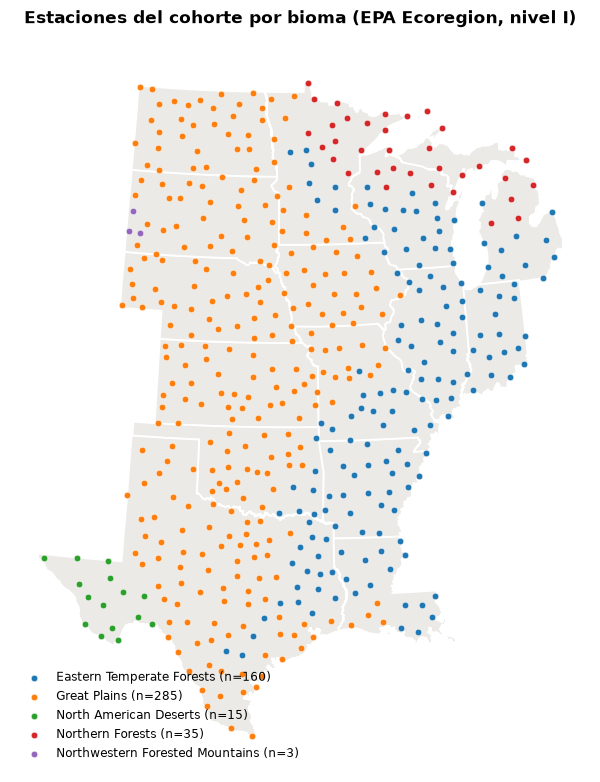

In [13]:
estados_mapa = gpd.read_file(PROCESSED + 'estados_central.geojson').to_crs(CRS_METRICO)
gdf = puntos.to_crs(CRS_METRICO)
gdf['bioma'] = datos['bioma']

fig, ax = plt.subplots(figsize=(11, 7), constrained_layout=True)
estados_mapa.plot(ax=ax, color='#ebeae6', edgecolor='white', linewidth=1.2, zorder=1)
for bioma, color in zip(sorted(gdf['bioma'].dropna().unique()), plt.cm.tab10.colors):
    sub = gdf[gdf['bioma'] == bioma]
    ax.scatter(sub.geometry.x, sub.geometry.y, s=18, color=color, label=f'{bioma} (n={len(sub)})',
               edgecolor='white', linewidth=0.3, zorder=2)
ax.legend(frameon=False, fontsize=8, loc='lower left')
ax.set_title('Estaciones del cohorte por bioma (EPA Ecoregion, nivel I)')
ax.set_axis_off()
figuras['00_mapa_biomas'] = fig
plt.show()

## 7. ¿Se sostienen los hallazgos de TP2 sobre agua, aeropuerto y área urbana?

Mismos tests que `hipotesis-agua-ciudades-aeropuertos.ipynb` (Spearman para las distancias continuas, Mann-Whitney
para los grupos binarios), con `area_urbana_km2` sumado a la lista de distancias. Se omite un test de grupo si algún
lado queda con menos de 5 estaciones (pasa con `sobre_agua`: sólo 4 estaciones cayeron sobre el agua). FDR de
Benjamini-Hochberg sobre el total de tests que sí se corren.

In [14]:
DISTANCIAS = [
    ('dist_agua_km', 'Distancia al agua (km)'),
    ('dist_aeropuerto_km', 'Distancia al aeropuerto (km)'),
    ('dist_area_urbana_km', 'Distancia al área urbana (km)'),
    ('area_urbana_km2', 'Tamaño del área urbana más cercana (km²)'),
]
GRUPOS = [('sobre_agua', 'Tierra', 'Agua'), ('en_area_urbana', 'Rural', 'Urbana')]

resultados_tp2 = []
for var, etiqueta in VARIABLES.items():
    for col_dist, etiqueta_dist in DISTANCIAS:
        sub = datos[[col_dist, f'abs_error_{var}']].dropna()
        rho, p = stats.spearmanr(sub[col_dist], sub[f'abs_error_{var}'])
        resultados_tp2.append(dict(variable=etiqueta, atributo=etiqueta_dist, tipo='Spearman (MAE)',
                                    efecto=round(rho, 3), p=p, n=len(sub)))

    for col_grupo, etiqueta_no, etiqueta_si in GRUPOS:
        for sufijo, nombre_tipo in [('abs_error', 'MAE'), ('error', 'sesgo')]:
            a = datos.loc[datos[col_grupo].fillna(False), f'{sufijo}_{var}'].dropna()
            b = datos.loc[~datos[col_grupo].fillna(False), f'{sufijo}_{var}'].dropna()
            if len(a) < 5 or len(b) < 5:
                continue
            _, p = stats.mannwhitneyu(a, b, alternative='two-sided')
            resultados_tp2.append(dict(variable=etiqueta, atributo=f'{etiqueta_si} vs. {etiqueta_no}',
                                        tipo=f'Mann-Whitney ({nombre_tipo})', efecto=round(a.mean() - b.mean(), 3),
                                        p=p, n=len(a) + len(b)))

tabla_tp2 = pd.DataFrame(resultados_tp2)
tabla_tp2['p_fdr'] = multipletests(tabla_tp2['p'], method='fdr_bh')[1]
tabla_tp2['significativo'] = tabla_tp2['p_fdr'] < 0.05
tabla_tp2 = tabla_tp2.sort_values('p_fdr').reset_index(drop=True)
print(f'{tabla_tp2["significativo"].sum()} de {len(tabla_tp2)} tests significativos tras FDR (q < 0,05)')
tabla_tp2.round(4)

6 de 24 tests significativos tras FDR (q < 0,05)


,variable,atributo,tipo,efecto,p,n,p_fdr,significativo
0,Viento (km/h),Distancia al agua (km),Spearman (MAE),0.357,0.0000,498,0.0000,True
1,Viento (km/h),Distancia al área urbana (km),Spearman (MAE),0.221,0.0000,498,0.0000,True
2,Humedad relativa (pp),Distancia al agua (km),Spearman (MAE),-0.170,0.0001,498,0.0011,True
3,Punto de rocío (°C),Distancia al área urbana (km),Spearman (MAE),0.160,0.0003,498,0.0019,True
4,Punto de rocío (°C),Distancia al agua (km),Spearman (MAE),-0.146,0.0011,498,0.0051,True
5,Punto de rocío (°C),Urbana vs. Rural,Mann-Whitney (MAE),-0.051,0.0074,498,0.0297,True
6,Punto de rocío (°C),Tamaño del área urbana más cercana (km²),Spearman (MAE),-0.108,0.0159,498,0.0544,False
7,Humedad relativa (pp),Urbana vs. Rural,Mann-Whitney (sesgo),-0.737,0.0223,498,0.0670,False
8,Temperatura (°C),Urbana vs. Rural,Mann-Whitney (sesgo),0.089,0.0252,498,0.0671,False
9,Viento (km/h),Distancia al aeropuerto (km),Spearman (MAE),0.089,0.0476,498,0.1038,False


### Lectura: la replicación es débil y, en varios casos, va al revés

**Sólo 6 de 24 tests dan significativos tras FDR**, contra 14 de 28 en TP2 -y no son los mismos hallazgos:

- **Agua**: en TP2 era el efecto más consistente de los tres (ρ entre 0,47 y 0,55 para temperatura/HR/punto de
  rocío, con el viento sin asociación). Acá sale **al revés**: HR (ρ = −0,170) y punto de rocío (ρ = −0,146) salen
  significativos pero con **signo negativo** -más cerca del agua, peor el pronóstico de humedad, lo opuesto a TP2- y
  el viento, que en TP2 no tenía asociación, ahora es el que más se asocia a la distancia al agua (ρ = 0,357, el
  efecto más fuerte de esta tabla).
- **Aeropuerto**: **ningún test sobrevive FDR** (el mejor, viento, ρ = 0,089, p_fdr = 0,10). En TP2 esta distancia
  era significativa para temperatura, HR y punto de rocío.
- **Área urbana**: el viento vuelve a aparecer, pero con signo invertido respecto a TP2 (ρ = 0,221: más lejos del
  área urbana, *peor* el pronóstico de viento) en vez del ρ = −0,33 de TP2 (más cerca, peor). El refinamiento nuevo,
  `area_urbana_km2`, no aporta nada que sobreviva FDR (mejor caso: punto de rocío, p_fdr = 0,054, justo afuera).

**La explicación más probable no es que la física haya cambiado, sino que cambió la composición de estaciones**: en
TP2, CENTERPOINT (Houston) tenía 148 de las 500 estaciones y era, por lejos, la red más grande -el propio TP2
dedicó una sección entera a controlar por esa confusión, y el hallazgo de viento urbano sobrevivía sin CENTERPOINT.
En el dataset de TP3, CENTERPOINT tiene apenas **2 de 498** estaciones; la red más grande ahora es `OTHER-MTR`
(187) y `ASOS-HFM` (136). El bloque de estaciones urbanas que sostenía el hallazgo de TP2 prácticamente no está en
esta muestra, así que no sorprende que el patrón no se repita igual -y con sólo 15 días de datos (contra lo que sea
que haya usado TP2) y apenas 4 estaciones sobre el agua, cualquier régimen sinóptico puntual de esas dos semanas
puede dominar una correlación con n chico.

**Conclusión para el feature set**: estos tres atributos son baratos de calcular (son estáticos, no hay que
mantenerlos) pero *no* hay que asumir que el signo o la magnitud que midió TP2 se van a sostener acá. Conviene
dejarlos como candidatos y que la selección de features del modelo (Etapa B: SHAP/feature importance) decida si
aportan, en vez de preseleccionarlos a mano por la literatura de TP2.

## 8. ¿Aporta el bioma información nueva?

El bioma tiene más de 2 categorías, así que no corre Mann-Whitney: se usa **Kruskal-Wallis**, el equivalente no
paramétrico de un ANOVA de una vía -compara más de dos grupos independientes a la vez. H0: las 4 (o 5) muestras
vienen de la misma distribución. Se excluye `Northwestern Forested Mountains` del test por tener sólo 3 estaciones
(`MIN_POR_BIOMA`), aunque se lo deja en los gráficos y en la tabla descriptiva.

In [15]:
MIN_POR_BIOMA = 10

conteo_bioma = datos['bioma'].value_counts()
biomas_validos = conteo_bioma[conteo_bioma >= MIN_POR_BIOMA].index
print(f'Biomas con >= {MIN_POR_BIOMA} estaciones: {len(biomas_validos)} de {conteo_bioma.size}')

resultados_bioma = []
for var, etiqueta in VARIABLES.items():
    for sufijo, nombre_tipo in [('abs_error', 'MAE'), ('error', 'sesgo')]:
        grupos = [datos.loc[datos['bioma'] == b, f'{sufijo}_{var}'].dropna() for b in biomas_validos]
        h, p = stats.kruskal(*grupos)
        resultados_bioma.append(dict(variable=etiqueta, tipo=f'Kruskal-Wallis ({nombre_tipo})', H=round(h, 2), p=p,
                                      n_biomas=len(grupos), n=sum(len(g) for g in grupos)))

tabla_bioma = pd.DataFrame(resultados_bioma)
tabla_bioma['p_fdr'] = multipletests(tabla_bioma['p'], method='fdr_bh')[1]
tabla_bioma['significativo'] = tabla_bioma['p_fdr'] < 0.05
tabla_bioma = tabla_bioma.sort_values('p_fdr').reset_index(drop=True)
print(f'{tabla_bioma["significativo"].sum()} de {len(tabla_bioma)} tests significativos tras FDR (q < 0,05)')
tabla_bioma.round(4)

Biomas con >= 10 estaciones: 4 de 5
7 de 8 tests significativos tras FDR (q < 0,05)


,variable,tipo,H,p,n_biomas,n,p_fdr,significativo
0,Viento (km/h),Kruskal-Wallis (MAE),94.91,0.0000,4,495,0.0000,True
1,Temperatura (°C),Kruskal-Wallis (MAE),53.11,0.0000,4,495,0.0000,True
2,Humedad relativa (pp),Kruskal-Wallis (MAE),46.66,0.0000,4,495,0.0000,True
3,Punto de rocío (°C),Kruskal-Wallis (MAE),37.01,0.0000,4,495,0.0000,True
4,Humedad relativa (pp),Kruskal-Wallis (sesgo),19.69,0.0002,4,495,0.0003,True
5,Temperatura (°C),Kruskal-Wallis (sesgo),13.52,0.0036,4,495,0.0048,True
6,Punto de rocío (°C),Kruskal-Wallis (sesgo),12.53,0.0058,4,495,0.0066,True
7,Viento (km/h),Kruskal-Wallis (sesgo),1.77,0.6221,4,495,0.6221,False


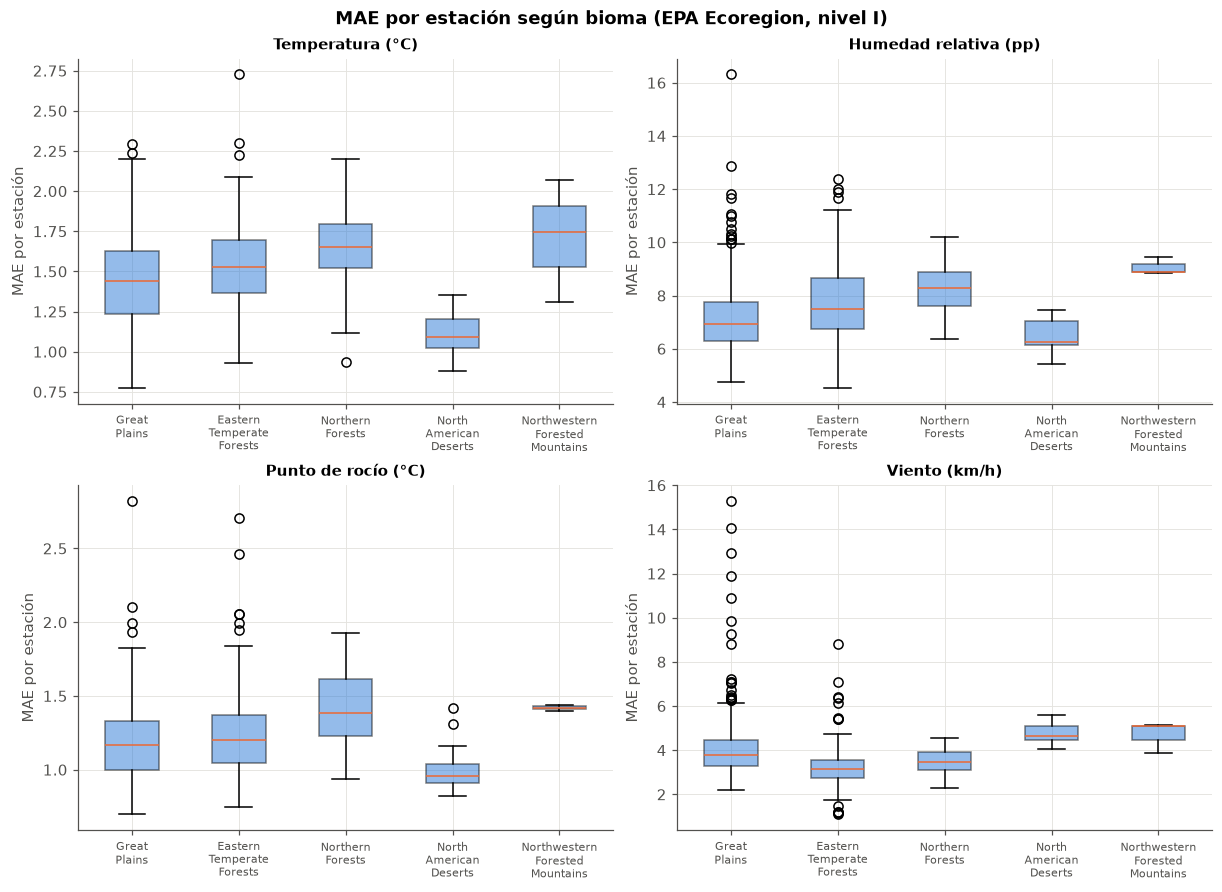

In [16]:
ORDEN_BIOMA = conteo_bioma.index.tolist()

fig, axes = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)
for ax, (var, etiqueta) in zip(axes.flat, VARIABLES.items()):
    grupos = [datos.loc[datos['bioma'] == b, f'abs_error_{var}'].dropna() for b in ORDEN_BIOMA]
    ax.boxplot(grupos, tick_labels=[b.replace(' ', '\n') for b in ORDEN_BIOMA], patch_artist=True,
               boxprops=dict(facecolor=AZUL, alpha=0.5), medianprops=dict(color=NARANJA))
    ax.set_title(etiqueta, fontsize=10)
    ax.set_ylabel('MAE por estación')
    ax.tick_params(axis='x', labelsize=7)
fig.suptitle('MAE por estación según bioma (EPA Ecoregion, nivel I)', fontweight='bold')
figuras['01_mae_por_bioma'] = fig
plt.show()

### Lectura: el hallazgo más limpio de todo el notebook

**7 de los 8 tests de bioma son significativos tras FDR**, y con p muy por debajo de 0,05 en los 4 del MAE (todos
p < 0,0001) -nada que ver con los p_fdr de 0,02-0,05 que raspaban la significancia en la sección anterior:

- **Viento** es donde el bioma más pesa (H = 94,91, el estadístico más alto de toda la tabla): la mediana de MAE va
  de 3,15 km/h en *Eastern Temperate Forests* a 5,09 km/h en *Northwestern Forested Mountains* -tiene sentido físico,
  el terreno complejo de montaña genera microclimas de viento que un modelo de grilla gruesa no puede resolver.
- **Temperatura, HR y punto de rocío** también separan con claridad (H entre 37 y 53, p < 0,0001): *North American
  Deserts* tiene el MAE más bajo de las 3 (1,09 °C / 6,26 pp / 0,96 °C) -clima más estable, menos frentes-, mientras
  que *Northern Forests* y *Northwestern Forested Mountains* son los peores en las tres.
- El sesgo con signo también es significativo en temperatura, HR y punto de rocío (p_fdr entre 0,0003 y 0,0066),
  **no** en viento (p_fdr = 0,62): el bioma cambia cuánto erra el pronóstico, pero no tan claramente hacia qué lado
  -salvo que en el error absoluto sí hay una dirección consistente (montaña y bosque boreal, peor).

**¿Es sólo agua/área urbana contado de nuevo?** No parece: `sobre_agua` es prácticamente 0 en los 5 biomas (máximo
6 % en *Northern Forests*, consistente con que ahí están los Grandes Lagos) y `en_area_urbana` varía entre 0 % y
34 % sin alinearse con el patrón de MAE de arriba (*Northwestern Forested Mountains*, el peor en todo, tiene 0 % de
estaciones urbanas). Tampoco es un artefacto de una sola red: CENTERPOINT (la confusión de TP2) tiene sólo 2
estaciones en total, las dos en *Great Plains*, lejos de ser suficiente para explicar un H de 94,91.

In [17]:
print('% sobre_agua y % en_area_urbana por bioma (chequeo de redundancia):')
print((datos.groupby('bioma')[['sobre_agua', 'en_area_urbana']].mean() * 100).round(0).astype(int))

print('\nEstaciones CENTERPOINT por bioma:')
print(pd.crosstab(datos['bioma'], datos['red'].eq('CENTERPOINT')).rename(columns={True: 'CENTERPOINT', False: 'otra red'}))

% sobre_agua y % en_area_urbana por bioma (chequeo de redundancia):
                                 sobre_agua  en_area_urbana
bioma                                                      
Eastern Temperate Forests                 1              34
Great Plains                              0              27
North American Deserts                    0               7
Northern Forests                          6              17
Northwestern Forested Mountains           0               0

Estaciones CENTERPOINT por bioma:
red                              otra red  CENTERPOINT
bioma                                                 
Eastern Temperate Forests             160            0
Great Plains                          283            2
North American Deserts                 15            0
Northern Forests                       35            0
Northwestern Forested Mountains         3            0


## 9. Síntesis: ¿qué conviene sumar a los modelos de la Etapa A?

| Dataset | ¿Aporta señal acá? | Recomendación |
|---|---|---|
| **Agua** (Natural Earth) | Débil y con signo invertido respecto a TP2 (sólo HR/punto de rocío, ρ ≈ −0,15/−0,17); el viento sale significativo (ρ = 0,36) donde antes no había nada. Apenas 4 estaciones sobre el agua. | Incluir `dist_agua_km` como candidato (es gratis, ya está calculado), pero **no** asumir el signo de TP2 -dejar que el modelo/SHAP lo pese. |
| **Aeropuerto** (OurAirports) | Ningún test sobrevive FDR en este dataset. | Incluir `dist_aeropuerto_km` igual (barato, estático) pero sin expectativa fuerte; si no aparece en feature importance, no va a sorprender. |
| **Área urbana** (TIGER) | El binario `UATYP20` nunca distinguió nada (sólo hay categoría `'U'`, en TP2 y acá). El refinamiento continuo (`area_urbana_km2`) tampoco llega a FDR. El viento vuelve a asociarse a esta distancia, pero con signo invertido respecto a TP2 -consistente con que CENTERPOINT, la red que sostenía ese hallazgo, casi no está en este dataset (2 de 498 vs. 148 de 500 en TP2). | Mantener `en_area_urbana` / `dist_area_urbana_km` (binario + distancia) como candidatos; **no** vale la pena sumar `area_urbana_km2`, no aporta sobre lo que ya daba la distancia. |
| **Bioma** (EPA Ecoregions) | El hallazgo más limpio del notebook: 7 de 8 tests significativos, p < 0,0001 en MAE para las 4 variables, con un patrón físicamente coherente (montaña/bosque boreal peor, desierto mejor) y sin redundancia aparente con agua/área urbana/red. | **Sumarlo** como feature categórica de estación (`bioma`, `NA_L1NAME`) -es la recomendación más firme de las cuatro. Al codificarlo (one-hot o frequency encoding), marcar o directamente excluir `Northwestern Forested Mountains` (n=3) de cualquier split de validación cruzada por grupo: ese tamaño de muestra es demasiado chico para generalizar, aunque el patrón en el boxplot sea consistente con el resto. |

**En conjunto**: de los 4 datasets nuevos, el que estaba *sin usar* (biomas) es el que más vale la pena agregar; los
3 que TP2 ya había validado siguen siendo candidatos razonables para incluir (son estáticos y no cuestan nada de
mantener), pero esta notebook muestra que sus hallazgos de TP2 no se replican con la misma fuerza ni el mismo signo
en esta ventana de datos -un recordatorio de que un atributo geográfico no es una verdad fija del terreno, sino que
su asociación con el error puede depender de qué estaciones y qué semanas entraron en la muestra. Por eso la Etapa
B (SHAP/feature importance) de la consigna es la que debería decidir, no esta exploración por sí sola.

## 10. Exportación

Se guardan los atributos geográficos por estación (para unir con el panel de features de `3_analisis_temporal.ipynb`
cuando se arme el dataset de modelado), las tablas de tests y las figuras.

In [18]:
import os

os.makedirs(OUT, exist_ok=True)

COLUMNAS_ATRIBUTOS = ['dist_costa_km', 'dist_lago_grande_km', 'dist_agua_km', 'sobre_agua', 'dist_aeropuerto_km',
                      'dist_area_urbana_km', 'en_area_urbana', 'area_urbana_km2', 'bioma']
datos[COLUMNAS_ATRIBUTOS].to_csv(PROCESSED + 'estaciones_atributos.csv')

tabla_tp2.to_csv(OUT + 'tabla_tp2_revisited.csv', index=False)
tabla_bioma.to_csv(OUT + 'tabla_bioma.csv', index=False)
for nombre, fig in figuras.items():
    fig.savefig(OUT + f'{nombre}.png', dpi=300, bbox_inches='tight', facecolor='white')

print(f'{PROCESSED}estaciones_atributos.csv: {len(datos)} estaciones, {len(COLUMNAS_ATRIBUTOS)} atributos')
print(f'Guardados: 2 tablas y {len(figuras)} figuras en {OUT}')

../data/processed/estaciones_atributos.csv: 498 estaciones, 9 atributos
Guardados: 2 tablas y 2 figuras en ../data/out/atributos_geograficos/
